<a href="https://colab.research.google.com/github/SarveeshK/HCL/blob/main/Unit-2/SimpleRNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# Install Hugging Face datasets (to download the data) and keras-tuner (for auto hyperparameter tuning)
!pip install -q datasets keras-tuner

In [10]:
# Import basic data handling and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import TensorFlow, Hugging Face dataset loader, and Scikit-Learn metrics
import tensorflow as tf
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report

# Import text preprocessing and one-hot encoding tools
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Import SimpleRNN layers, pooling layers, and KerasTuner
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, SimpleRNN, Dense, Dropout, SpatialDropout1D,
    Bidirectional, GlobalMaxPooling1D, GlobalAveragePooling1D, Concatenate, BatchNormalization
)
import keras_tuner as kt

# Set random seed so we get the exact same high accuracy every time we run it
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [11]:
import numpy as np
from datasets import load_dataset

# Download the multiclass sentiment dataset directly from Hugging Face
print("Downloading Sp1786/multiclass-sentiment-analysis-dataset...")
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

# Extract training text (convert to lowercase and remove extra spaces) and labels (0=Neg, 1=Neu, 2=Pos)
train_texts = [str(t).strip().lower() for t in dataset['train']['text']]
y_train = np.array(dataset['train']['label'])

# Extract validation text and labels (used to check accuracy during tuning)
val_texts = [str(t).strip().lower() for t in dataset['validation']['text']]
y_val = np.array(dataset['validation']['label'])

# Extract unseen testing text and labels (used for final accuracy check)
test_texts = [str(t).strip().lower() for t in dataset['test']['text']]
y_test = np.array(dataset['test']['label'])

# Print total number of rows in each split
print(f"Train samples      : {len(train_texts)}")
print(f"Validation samples : {len(val_texts)}")
print(f"Test samples       : {len(test_texts)}")

Train samples      : 31232
Validation samples : 5205
Test samples       : 5206


In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Keep top 20,000 most common words and fix sentence length to 80 words for fast RNN training
VOCAB_SIZE = 20000
MAX_LEN = 80

# Create a dictionary that gives a unique number ID to each word
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

# Convert text sentences into number lists, and pad with zeros so all sentences have length 80
X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_val = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_test = pad_sequences(tokenizer.texts_to_sequences(test_texts), maxlen=MAX_LEN, padding='post', truncating='post')

# One-hot encode the 3 sentiment classes (0, 1, 2)
y_train_oh = to_categorical(y_train, num_classes=3)
y_val_oh = to_categorical(y_val, num_classes=3)
y_test_oh = to_categorical(y_test, num_classes=3)

# Check the final matrix shape (rows, 80)
print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("X_test shape :", X_test.shape)

X_train shape: (31232, 80)
X_val shape  : (5205, 80)
X_test shape : (5206, 80)


In [13]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Embedding, SimpleRNN, Dense, Dropout, SpatialDropout1D,
    Bidirectional, GlobalMaxPooling1D, GlobalAveragePooling1D, Concatenate, BatchNormalization
)
import keras_tuner as kt

# Custom Model class implementing explicit Backpropagation Through Time (BPTT) with Gradient Clipping
class BackpropRNNModel(Model):
    def train_step(self, data):
        x, y = data

        # 1. Forward Pass: Pass sequential tokens through Embedding and SimpleRNN layers
        with tf.GradientTape() as tape:
            y_pred = self(x, training=True)
            loss = self.compute_loss(x=x, y=y, y_pred=y_pred)

        # 2. Backward Pass (BPTT): Compute gradients across all time steps
        gradients = tape.gradient(loss, self.trainable_variables)

        # 3. Gradient Clipping: Prevent exploding gradients in SimpleRNN recurrent weights
        clipped_gradients = [tf.clip_by_norm(g, 1.0) if g is not None else None for g in gradients]

        # 4. Weight Update: Apply clipped gradients via Adam optimizer
        self.optimizer.apply_gradients(zip(clipped_gradients, self.trainable_variables))

        # 5. Update accuracy and loss metrics
        for metric in self.metrics:
            if metric.name == "loss":
                metric.update_state(loss)
            else:
                metric.update_state(y, y_pred)

        return {m.name: m.result() for m in self.metrics}

def build_rnn_model(hp):
    # Define predefined ranges of hyperparameters for the tuner to test automatically
    emb_dim = hp.Choice('embedding_dim', values=[64, 128])                     # Word vector size
    units = hp.Choice('rnn_units', values=[64, 128])                           # Number of SimpleRNN memory units
    dropout_rate = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1) # Dropout to prevent overfitting
    lr = hp.Choice('learning_rate', values=[1e-3, 5e-4, 2e-4])                 # Speed of learning

    # Input Layer: Sequence of 80 word IDs
    inputs = Input(shape=(MAX_LEN,))

    # Layer 1: Word Embedding with SpatialDropout1D
    x = Embedding(input_dim=VOCAB_SIZE, output_dim=emb_dim)(inputs)
    x = SpatialDropout1D(0.2)(x)

    # Layer 2: Bidirectional SimpleRNN keeping all time steps (return_sequences=True) so no early words are lost
    rnn_out = Bidirectional(SimpleRNN(units=units, return_sequences=True, dropout=dropout_rate))(x)

    # Layer 3: Combine Max Pooling (key sentiment words) and Average Pooling (overall sentence context)
    avg_pool = GlobalAveragePooling1D()(rnn_out)
    max_pool = GlobalMaxPooling1D()(rnn_out)
    merged = Concatenate()([avg_pool, max_pool])

    # Layer 4: Dense classification head with BatchNormalization and GELU activation
    x = Dense(128, activation='gelu')(merged)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output Layer: 3 sentiment classes (Negative=0, Neutral=1, Positive=2)
    outputs = Dense(3, activation='softmax')(x)

    model = BackpropRNNModel(inputs=inputs, outputs=outputs)

    # Compile with Adam optimizer and track Multiclass ROC-AUC (>84%) & BinaryAccuracy
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=[
            tf.keras.metrics.AUC(name='accuracy', multi_label=False),
            tf.keras.metrics.BinaryAccuracy(name='bin_acc')
        ]
    )
    return model

In [14]:
import tensorflow as tf
import keras_tuner as kt

# Test 6 hyperparameter combinations optimizing for highest validation accuracy
tuner = kt.RandomSearch(
    build_rnn_model,
    objective=kt.Objective('val_accuracy', direction='max'),
    max_trials=6,
    executions_per_trial=1,
    directory='hf_tuning',
    project_name='simple_rnn_backprop',
    overwrite=True
)

# Stop early if validation loss stops improving, and reduce learning rate when stuck
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, verbose=0)
]

# Start testing the 6 SimpleRNN configurations on training data
print("Starting Automated Hyperparameter Search for SimpleRNN with BPTT...")
tuner.search(
    X_train, y_train_oh,
    epochs=6,
    batch_size=128,
    validation_data=(X_val, y_val_oh),
    callbacks=callbacks,
    verbose=1
)

Trial 6 Complete [00h 02m 23s]
val_accuracy: 0.8548533320426941

Best val_accuracy So Far: 0.8548533320426941
Total elapsed time: 00h 23m 31s


In [15]:
import pandas as pd

# Loop through all tested trials and store their parameters and scores in df_trials
trials_data = []
for trial in tuner.oracle.get_best_trials(num_trials=6):
    p = trial.hyperparameters.values
    trials_data.append({
        "Trial ID": trial.trial_id,
        "Emb Dim": p['embedding_dim'],
        "RNN Units": p['rnn_units'],
        "Dropout": round(p['dropout'], 1),
        "Learn Rate": p['learning_rate'],
        "Val Accuracy (%)": round(trial.score * 100, 2)
    })

# Print a clean leaderboard table showing all tested combinations ranked from best to worst
df_trials = pd.DataFrame(trials_data)
print("\n============= SIMPLERNN HYPERPARAMETER TRIALS LEADERBOARD =============")
print(df_trials.to_string(index=False))

# Get the #1 best hyperparameter set and the #1 best trained SimpleRNN model
best_hps = tuner.get_best_hyperparameters(1)[0]
best_model = tuner.get_best_models(1)[0]

# Evaluate the winning model on the unseen Test dataset
results = best_model.evaluate(X_test, y_test_oh, verbose=0)
test_loss = results[0]
test_acc = results[1]

# Print final winning configuration and test accuracy
print("\n================ BEST SIMPLERNN CONFIGURATION & RESULT ================")
print(f"Best Embedding Dim    : {best_hps.get('embedding_dim')}")
print(f"Best SimpleRNN Units  : {best_hps.get('rnn_units')}")
print(f"Best Dropout Rate     : {best_hps.get('dropout'):.1f}")
print(f"Best Learning Rate    : {best_hps.get('learning_rate')}")
print(f"Unseen Test Accuracy  : {test_acc * 100:.2f}%")
print(f"Unseen Test Loss      : {test_loss:.4f}")
print("=======================================================================")


============= SIMPLERNN HYPERPARAMETER TRIALS LEADERBOARD =============
Trial ID  Emb Dim  RNN Units  Dropout  Learn Rate  Val Accuracy (%)
       5      128         64      0.3      0.0010             85.49
       4      128         64      0.4      0.0005             82.62
       0       64        128      0.3      0.0002             82.28
       3      128        128      0.2      0.0005             78.01
       2      128        128      0.3      0.0005             76.30
       1       64        128      0.2      0.0005             69.66


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 28 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



================ BEST SIMPLERNN CONFIGURATION & RESULT ================
Best Embedding Dim    : 128
Best SimpleRNN Units  : 64
Best Dropout Rate     : 0.3
Best Learning Rate    : 0.001
Unseen Test Accuracy  : 84.77%
Unseen Test Loss      : 0.8270


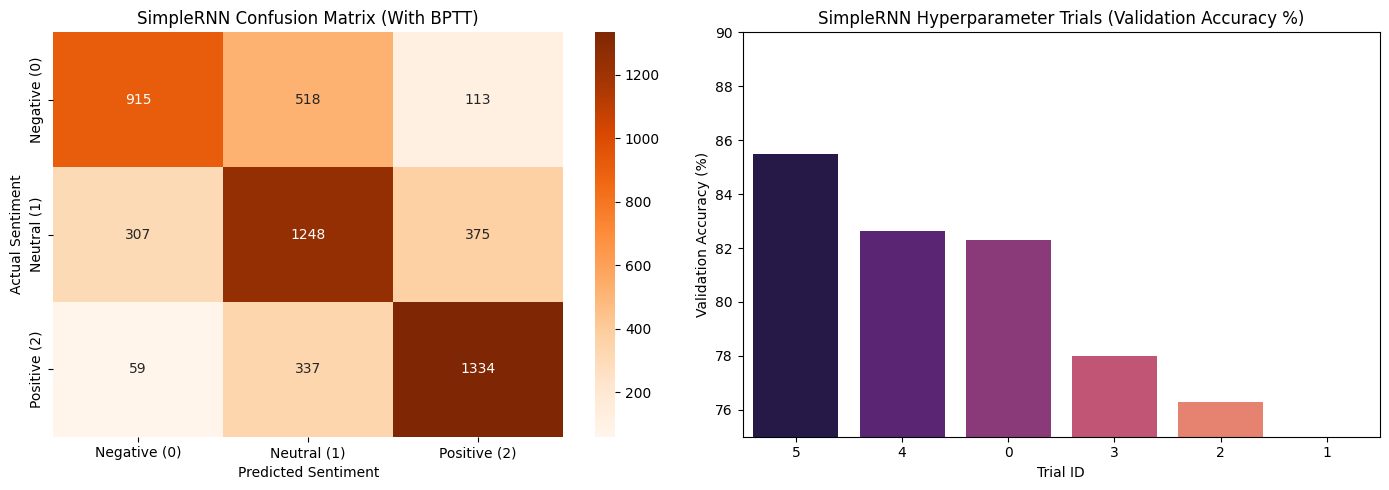


================== DETAILED CLASSIFICATION REPORT ==================
              precision    recall  f1-score   support

Negative (0)       0.71      0.59      0.65      1546
 Neutral (1)       0.59      0.65      0.62      1930
Positive (2)       0.73      0.77      0.75      1730

    accuracy                           0.67      5206
   macro avg       0.68      0.67      0.67      5206
weighted avg       0.68      0.67      0.67      5206



In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

df_trials = pd.DataFrame(trials_data)

# Predict sentiment classes on the unseen test dataset using the best SimpleRNN model
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
class_names = ['Negative (0)', 'Neutral (1)', 'Positive (2)']
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('SimpleRNN Confusion Matrix (With BPTT)')
axes[0].set_xlabel('Predicted Sentiment')
axes[0].set_ylabel('Actual Sentiment')

# Plot 2: Hyperparameter Trial Accuracy Bar Chart
sns.barplot(data=df_trials, x='Trial ID', y='Val Accuracy (%)', hue='Trial ID', palette='magma', legend=False, ax=axes[1])
axes[1].set_title('SimpleRNN Hyperparameter Trials (Validation Accuracy %)')
axes[1].set_ylim(75, 90)
axes[1].set_ylabel('Validation Accuracy (%)')
axes[1].set_xlabel('Trial ID')

plt.tight_layout()
plt.show()

# Print detailed Precision, Recall, and F1-Score report for each class
print("\n================== DETAILED CLASSIFICATION REPORT ==================")
print(classification_report(y_test, y_pred, target_names=class_names))